## BRIEF DESCRIPTION

Workforce Intelligence & HR Analytics is an end-to-end HR analytics project focused on employee lifecycle, workforce composition, compensation, performance, engagement, and retention. Using a fictional company's HR dataset, the project applies data profiling, quality validation, exploratory data analysis, and business intelligence to transform employee records into actionable workforce insights.

The analysis examines headcount distribution, employee turnover, tenure, termination reasons, salary patterns, recruitment sources, absenteeism, performance scores, and employee engagement. It also evaluates employee-register integrity by identifying duplicate employee IDs, repeated names, missing values, invalid records, and inconsistencies between employment status, termination flags, and termination dates.

The project aims to develop reliable HR metrics, uncover workforce trends, and support evidence-based decision-making in workforce planning, retention management, compensation monitoring, and performance reporting. Findings will inform an executive-ready HR dashboard and management recommendations, with clear documentation of metric definitions, assumptions, data-quality limitations, and analytical methods.

**Tools:** Python, Pandas, SQL, Power BI

**Business value:** Demonstrates how data analytics can strengthen HR reporting, improve data integrity, and support strategic workforce decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [2]:
chunk_list = []

files = [
    r"/Users/mac/Desktop/Workforce-Intelligence-HR-Analytics-Employee-Lifecycle-Compensation-and-Performance-Analysis/Dataset/HRDataset_v14.csv"

]

for file in files:
    for chunk in pd.read_csv(file, dtype={"SiMessageId": "string"}, chunksize=50000):
        chunk_list.append(chunk)

# Combine everything
df = pd.concat(chunk_list, ignore_index=True)

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 38 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    object 
 1   First Name                  311 non-null    object 
 2   Last Name                   311 non-null    object 
 3   EmpID                       311 non-null    int64  
 4   MarriedID                   311 non-null    int64  
 5   MaritalStatusID             311 non-null    int64  
 6   GenderID                    311 non-null    int64  
 7   EmpStatusID                 311 non-null    int64  
 8   DeptID                      311 non-null    int64  
 9   PerfScoreID                 311 non-null    int64  
 10  FromDiversityJobFairID      311 non-null    int64  
 11  Salary                      311 non-null    int64  
 12  Termd                       311 non-null    int64  
 13  PositionID                  311 non

In [3]:
df.head()

,Employee_Name,First Name,Last Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,...,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",Adinolfi,Wilson,10026,0,0,1,1,5,4,...,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",Ait Sidi,Karthikeyan,10084,1,1,1,5,3,3,...,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",Akinkuolie,Sarah,10196,1,1,0,5,5,3,...,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,"Alagbe,Trina",Alagbe,Alagbe,10088,1,1,0,1,5,3,...,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,"Anderson, Carol",Anderson,Carol,10069,0,2,0,5,5,3,...,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [4]:
# Standardise column names for checking
df.columns = df.columns.str.strip()


In [5]:

required_columns = [
    "EmpID",
    "Employee_Name",
    "Termd",
    "EmploymentStatus",
    "DateofTermination"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )


In [6]:

# 2. Standardise fields used in the checks
# Preserve the original dataframe; use a working copy.
work = df.copy()

work["EmpID"] = work["EmpID"].astype("string").str.strip()
work["Employee_Name"] = (
    work["Employee_Name"].astype("string").str.strip()
)

work["EmploymentStatus_clean"] = (
    work["EmploymentStatus"].astype("string").str.strip().str.casefold()
)

work["Termd_clean"] = (
    work["Termd"].astype("string").str.strip().str.casefold()
)

work["DateofTermination_clean"] = pd.to_datetime(
    work["DateofTermination"],
    errors="coerce"
)


/var/folders/tk/fdypsrw94kg40x6m2x674k_m0000gn/T/ipykernel_52048/313273827.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  work["DateofTermination_clean"] = pd.to_datetime(


In [7]:
work[["EmploymentStatus", "Termd_clean","DateofTermination_clean"]].head()

,EmploymentStatus,Termd_clean,DateofTermination_clean
0,Active,0,NaT
1,Voluntarily Terminated,1,2016-06-16
2,Voluntarily Terminated,1,2012-09-24
3,Active,0,NaT
4,Voluntarily Terminated,1,2016-09-06


In [8]:

# 3. Total rows and distinct employee IDs
total_rows = len(work)
distinct_ids = work["EmpID"].nunique(dropna=True)
missing_ids = work["EmpID"].isna() | work["EmpID"].eq("")

print("=" * 65)
print("EMPLOYEE REGISTER PROFILE")
print("=" * 65)
print(f"Total rows: {total_rows:,}")
print(f"Distinct non-missing EmpIDs: {distinct_ids:,}")
print(f"Rows with missing/blank EmpID: {missing_ids.sum():,}")
print(f"Duplicate EmpID occurrences beyond first: "
      f"{work.loc[~missing_ids, 'EmpID'].duplicated().sum():,}")


EMPLOYEE REGISTER PROFILE
Total rows: 311
Distinct non-missing EmpIDs: 311
Rows with missing/blank EmpID: 0
Duplicate EmpID occurrences beyond first: 0


In [9]:

# 4. Check whether an employee ID occurs more than once
valid_id_rows = work.loc[~missing_ids].copy()

duplicate_id_summary = (
    valid_id_rows.groupby("EmpID", dropna=False)
    .agg(
        Row_Count=("EmpID", "size"),
        Name_Variants=("Employee_Name", "nunique"),
        Status_Variants=("EmploymentStatus_clean", "nunique")
    )
    .query("Row_Count > 1")
    .reset_index()
    .sort_values("Row_Count", ascending=False)
)

duplicate_id_rows = valid_id_rows[
    valid_id_rows["EmpID"].isin(duplicate_id_summary["EmpID"])
].sort_values("EmpID")

print("\n" + "=" * 65)
print("DUPLICATE EMPLOYEE IDs")
print("=" * 65)
print(f"Employee IDs appearing more than once: "
      f"{len(duplicate_id_summary):,}")

if duplicate_id_summary.empty:
    print("No repeated non-missing employee IDs found.")
else:
    display(duplicate_id_summary)
    print("Detailed records for repeated IDs:")
    display(duplicate_id_rows[
        ["EmpID", "Employee_Name", "EmploymentStatus",
         "Termd", "DateofTermination"]
    ])



DUPLICATE EMPLOYEE IDs
Employee IDs appearing more than once: 0
No repeated non-missing employee IDs found.


In [10]:

# 5. Check repeated names associated with different IDs
valid_names = work[
    work["Employee_Name"].notna()
    & work["Employee_Name"].ne("")
    & ~missing_ids
].copy()

valid_names["Name_Key"] = (
    valid_names["Employee_Name"].str.casefold()
)

repeated_name_summary = (
    valid_names.groupby("Name_Key")
    .agg(
        Displayed_Name=("Employee_Name", "first"),
        Distinct_EmpIDs=("EmpID", "nunique"),
        Row_Count=("EmpID", "size")
    )
    .query("Distinct_EmpIDs > 1")
    .reset_index()
    .sort_values(["Distinct_EmpIDs", "Row_Count"], ascending=False)
)

repeated_name_rows = valid_names[
    valid_names["Name_Key"].isin(repeated_name_summary["Name_Key"])
].sort_values(["Name_Key", "EmpID"])

print("\n" + "=" * 65)
print("REPEATED NAMES WITH DIFFERENT EMPLOYEE IDs")
print("=" * 65)
print(f"Names linked to multiple distinct EmpIDs: "
      f"{len(repeated_name_summary):,}")

if repeated_name_summary.empty:
    print("No repeated names linked to different employee IDs found.")
else:
    display(repeated_name_summary[
        ["Displayed_Name", "Distinct_EmpIDs", "Row_Count"]
    ])
    display(repeated_name_rows[
        ["EmpID", "Employee_Name", "EmploymentStatus",
         "Termd", "DateofTermination"]
    ])



REPEATED NAMES WITH DIFFERENT EMPLOYEE IDs
Names linked to multiple distinct EmpIDs: 0
No repeated names linked to different employee IDs found.


In [ ]:

# 5. Check whether active and terminated employees coexist
status_counts = (
    work["EmploymentStatus_clean"]
    .fillna("<missing>")
    .value_counts()
    .rename_axis("EmploymentStatus")
    .reset_index(name="Rows")
)

active_mask = work["EmploymentStatus_clean"].eq("active")
terminated_mask = work["EmploymentStatus_clean"].eq("terminated")

print("\n" + "=" * 65)
print("EMPLOYMENT STATUS DISTRIBUTION")
print("=" * 65)
display(status_counts)

has_active = active_mask.any()
has_terminated = terminated_mask.any()

print(f"Active-status rows present: {has_active}")
print(f"Terminated-status rows present: {has_terminated}")
print(f"Both statuses present in the same table: "
      f"{has_active and has_terminated}")



EMPLOYMENT STATUS DISTRIBUTION


,EmploymentStatus,Rows
0,active,207
1,voluntarily terminated,88
2,terminated for cause,16


Active-status rows present: True
Terminated-status rows present: False
Both statuses present in the same table: False


In [ ]:

# 6. Reconcile status flag, status text, and termination date
# Expected interpretation for the commonly used HRDataset:
# Termd = 1 means terminated; Termd = 0 means not terminated.
# Validate this interpretation against the dataset documentation.

flag_map = {
    "1": True,
    "1.0": True,
    "true": True,
    "yes": True,
    "0": False,
    "0.0": False,
    "false": False,
    "no": False
}

work["Termd_bool"] = work["Termd_clean"].map(flag_map)

work["Status_says_terminated"] = work[
    "EmploymentStatus_clean"
].eq("terminated")

work["Has_termination_date"] = work[
    "DateofTermination_clean"
].notna()

# Only evaluate dates/status flags where their values can be interpreted.
work["Flag_vs_Status_mismatch"] = (
    work["Termd_bool"].notna()
    & work["EmploymentStatus_clean"].isin(["active", "terminated"])
    & work["Termd_bool"].ne(work["Status_says_terminated"])
)

work["Flag_vs_Date_mismatch"] = (
    work["Termd_bool"].notna()
    & work["Termd_bool"].ne(work["Has_termination_date"])
)

work["Status_vs_Date_mismatch"] = (
    work["EmploymentStatus_clean"].isin(["active", "terminated"])
    & work["Status_says_terminated"].ne(work["Has_termination_date"])
)

# Identify records where one or more checks fail, or key values are unknown.
work["Status_check_unresolved"] = (
    work["Termd_bool"].isna()
    | ~work["EmploymentStatus_clean"].isin(["active", "terminated"])
)

work["Any_reconciliation_issue"] = (
    work["Flag_vs_Status_mismatch"]
    | work["Flag_vs_Date_mismatch"]
    | work["Status_vs_Date_mismatch"]
    | work["Status_check_unresolved"]
)

reconciliation_columns = [
    "EmpID",
    "Employee_Name",
    "Termd",
    "EmploymentStatus",
    "DateofTermination",
    "Flag_vs_Status_mismatch",
    "Flag_vs_Date_mismatch",
    "Status_vs_Date_mismatch",
    "Status_check_unresolved"
]

print("\n" + "=" * 65)
print("STATUS RECONCILIATION RESULTS")
print("=" * 65)
print(f"Termd vs EmploymentStatus mismatches: "
      f"{work['Flag_vs_Status_mismatch'].sum():,}")
print(f"Termd vs termination-date mismatches: "
      f"{work['Flag_vs_Date_mismatch'].sum():,}")
print(f"EmploymentStatus vs termination-date mismatches: "
      f"{work['Status_vs_Date_mismatch'].sum():,}")
print(f"Records with unresolved status/flag values: "
      f"{work['Status_check_unresolved'].sum():,}")
print(f"Records with at least one issue or unresolved check: "
      f"{work['Any_reconciliation_issue'].sum():,}")

reconciliation_issues = work.loc[
    work["Any_reconciliation_issue"],
    reconciliation_columns
]

if reconciliation_issues.empty:
    print("No mismatches or unresolved status checks found.")
else:
    display(reconciliation_issues)



STATUS RECONCILIATION RESULTS
Termd vs EmploymentStatus mismatches: 0
Termd vs termination-date mismatches: 0
EmploymentStatus vs termination-date mismatches: 0
Records with unresolved status/flag values: 104
Records with at least one issue or unresolved check: 104


,EmpID,Employee_Name,Termd,EmploymentStatus,DateofTermination,Flag_vs_Status_mismatch,Flag_vs_Date_mismatch,Status_vs_Date_mismatch,Status_check_unresolved
1,10084,"Ait Sidi, Karthikeyan",1,Voluntarily Terminated,6/16/16,False,False,False,True
2,10196,"Akinkuolie, Sarah",1,Voluntarily Terminated,9/24/12,False,False,False,True
4,10069,"Anderson, Carol",1,Voluntarily Terminated,9/6/16,False,False,False,True
10,10252,"Baczenski, Rachael",1,Voluntarily Terminated,1/12/17,False,False,False,True
11,10242,"Barbara, Thomas",1,Voluntarily Terminated,9/19/16,False,False,False,True
...,...,...,...,...,...,...,...,...,...
301,10048,"Wilber, Barry",1,Voluntarily Terminated,9/7/15,False,False,False,True
302,10204,"Wilkes, Annie",1,Voluntarily Terminated,5/14/12,False,False,False,True
303,10264,"Williams, Jacquelyn",1,Voluntarily Terminated,6/27/15,False,False,False,True
304,10033,"Winthrop, Jordan",1,Voluntarily Terminated,2/21/16,False,False,False,True


In [ ]:

# 7. save the exceptions for review

# Create output folder if it doesn't exist
output_dir = Path("/Users/mac/Desktop/Workforce-Intelligence-HR-Analytics-Employee-Lifecycle-Compensation-and-Performance-Analysis/output")
output_dir.mkdir(parents=True, exist_ok=True)

duplicate_id_rows.to_csv(output_dir / "duplicate_employee_ids.csv", index=False)
repeated_name_rows.to_csv(output_dir / "repeated_names_different_ids.csv", index=False)
reconciliation_issues.to_csv(output_dir / "employment_status_exceptions.csv", index=False)

print("\nException files exported for review.")



Exception files exported for review.


### Data-quality observation and validation caveat

The employee-register checks found **311 rows, 311 distinct employee IDs, no missing IDs, no duplicate IDs, and no repeated employee names linked to different IDs**. The dataset also has 104 non-null termination dates and 8 missing `ManagerID` values (303 of 311 are populated).

**Important correction required before relying on the status reconciliation result:** the current reconciliation code checks whether `EmploymentStatus` equals exactly `"terminated"`, but the actual dataset uses `"Voluntarily Terminated"` and `"Terminated for Cause"`. Consequently, the code's “0 mismatches” result does not fully validate the status text, and the 104 “unresolved” records are likely caused by this overly narrow label check. Update the logic to recognise any status containing `"terminated"` (case-insensitively), then rerun the reconciliation cell before treating the results as a confirmed quality finding.

The `DateofTermination` field being populated for terminated records and blank for active records is expected for this type of employee snapshot. The eight missing manager IDs should be reviewed, especially if manager-level reporting is required.

## BUSINESS QUESTIONS

## 1. What does the workforce look like across departments, positions and employment statuses, and how has headcount changed over time?
Why the CPO cares: Workforce planning, resource allocation and management reporting.
KPIs: Active headcount, hires, exits, net headcount change and departmental workforce distribution.

In [ ]:
# ==========================================
# EMPLOYMENT STATUS DISTRIBUTION
# ==========================================

employment_status = (
    df["EmploymentStatus"]
    .fillna("Unknown")
    .value_counts()
    .rename_axis("EmploymentStatus")
    .reset_index(name="EmployeeCount")
)

employment_status["Percentage"] = (
    employment_status["EmployeeCount"] / len(df) * 100
).round(2)

print("\nEMPLOYMENT STATUS DISTRIBUTION")
print(employment_status.to_string(index=False))

employment_status.to_csv(
    output_dir / "employment_status_distribution.csv", index=False
)

# ==========================================
#  WORKFORCE BY DEPARTMENT
# ==========================================

department_summary = (
    df.groupby("Department", dropna=False)
    .agg(
        TotalEmployees=("EmpID", "nunique"),
        ActiveEmployees=(
            "EmploymentStatus",
            lambda x: x.eq("Active").sum()
        ),
        TerminatedEmployees=("Termd", lambda x: x.eq(1).sum())
    )
    .reset_index()
    .sort_values("TotalEmployees", ascending=False)
)

department_summary["WorkforcePercentage"] = (
    department_summary["TotalEmployees"] / df["EmpID"].nunique() * 100
).round(2)

print("\nWORKFORCE BY DEPARTMENT")
print(department_summary.to_string(index=False))

department_summary.to_csv(
    output_dir / "workforce_by_department.csv", index=False
)

# ==========================================
#  WORKFORCE BY POSITION
# ==========================================

position_summary = (
    df.groupby(["PositionID", "Position"], dropna=False)
    .agg(
        TotalEmployees=("EmpID", "nunique"),
        ActiveEmployees=(
            "EmploymentStatus",
            lambda x: x.eq("Active").sum()
        ),
        TerminatedEmployees=("Termd", lambda x: x.eq(1).sum())
    )
    .reset_index()
    .sort_values("TotalEmployees", ascending=False)
)

print("\nWORKFORCE BY POSITION")
print(position_summary.to_string(index=False))

position_summary.to_csv(
    output_dir / "workforce_by_position.csv", index=False
)

# ==========================================
#  DEPARTMENT x EMPLOYMENT STATUS
# ==========================================

department_status = pd.crosstab(
    df["Department"].fillna("Unknown"),
    df["EmploymentStatus"].fillna("Unknown"),
    margins=True
)

print("\nDEPARTMENT BY EMPLOYMENT STATUS")
print(department_status)

department_status.to_csv(
    output_dir / "department_by_employment_status.csv"
)

# ==========================================
#  MONTHLY HIRES
# ==========================================

hires = df.dropna(subset=["DateofHire"]).copy()

df["DateofHire"] = pd.to_datetime(
    df["DateofHire"].astype("string").str.strip(),
    errors="coerce"
)

hires["HireMonth"] = (
    hires["DateofHire"].dt.to_period("M").astype(str)
)

monthly_hires = (
    hires.groupby("HireMonth")
    .agg(NewHires=("EmpID", "nunique"))
    .reset_index()
    .sort_values("HireMonth")
)

print("\nMONTHLY HIRES")
print(monthly_hires.to_string(index=False))

monthly_hires.to_csv(
    output_dir / "monthly_hires.csv", index=False
)

# ==========================================
# 8. MONTHLY TERMINATIONS
# ==========================================

terminations = df.dropna(subset=["DateofTermination"]).copy()

terminations["TerminationMonth"] = (
    terminations["DateofTermination"].dt.to_period("M").astype(str)
)

monthly_terminations = (
    terminations.groupby("TerminationMonth")
    .agg(Terminations=("EmpID", "nunique"))
    .reset_index()
    .sort_values("TerminationMonth")
)

print("\nMONTHLY TERMINATIONS")
print(monthly_terminations.to_string(index=False))

monthly_terminations.to_csv(
    output_dir / "monthly_terminations.csv", index=False
)

# ==========================================
# 9. HISTORICAL MONTH-END HEADCOUNT
# ==========================================

# Use the earliest hire date through the latest hire or termination date.
valid_dates = pd.concat(
    [df["DateofHire"], df["DateofTermination"]]
).dropna()

if not valid_dates.empty:
    start_date = df["DateofHire"].min()
    end_date = valid_dates.max()

    if pd.notna(start_date):
        months = pd.period_range(
            start=start_date.to_period("M"),
            end=end_date.to_period("M"),
            freq="M"
        )

        headcount_records = []

        for month in months:
            month_end = month.end_time.normalize()

            # Assumption: an employee is counted at month-end if
            # hired on/before month-end and not terminated before
            # month-end. Termination date is treated as the last
            # employed day.
            employed = (
                df["DateofHire"].notna()
                & (df["DateofHire"] <= month_end)
                & (
                    df["DateofTermination"].isna()
                    | (df["DateofTermination"] >= month_end)
                )
            )

            headcount_records.append({
                "Month": str(month),
                "MonthEnd": month_end,
                "Headcount": df.loc[employed, "EmpID"].nunique()
            })

        monthly_headcount = pd.DataFrame(headcount_records)

        # Add monthly hires and exits for comparison
        monthly_headcount = monthly_headcount.merge(
            monthly_hires.rename(
                columns={"HireMonth": "Month"}
            ),
            on="Month",
            how="left"
        )

        monthly_headcount = monthly_headcount.merge(
            monthly_terminations.rename(
                columns={"TerminationMonth": "Month"}
            ),
            on="Month",
            how="left"
        )

        monthly_headcount[["NewHires", "Terminations"]] = (
            monthly_headcount[["NewHires", "Terminations"]]
            .fillna(0)
            .astype(int)
        )

        monthly_headcount["NetChange"] = (
            monthly_headcount["NewHires"]
            - monthly_headcount["Terminations"]
        )

        monthly_headcount["HeadcountChange"] = (
            monthly_headcount["Headcount"].diff()
        )

        print("\nMONTHLY HEADCOUNT TREND")
        print(monthly_headcount.to_string(index=False))

        monthly_headcount.to_csv(
            output_dir / "monthly_headcount_trend.csv",
            index=False
        )

        # Headcount trend chart
        plt.figure(figsize=(14, 6))
        sns.lineplot(
            data=monthly_headcount,
            x="Month",
            y="Headcount",
            marker="o"
        )
        plt.title("Historical Month-End Workforce Headcount")
        plt.xlabel("Month")
        plt.ylabel("Employee Headcount")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.savefig(
            output_dir / "monthly_headcount_trend.png",
            dpi=300
        )
        plt.show()

# ==========================================
#  VISUALISE WORKFORCE BY DEPARTMENT
# ==========================================

plt.figure(figsize=(12, 6))
sns.barplot(
    data=department_summary,
    x="TotalEmployees",
    y="Department"
)
plt.title("Workforce Distribution by Department")
plt.xlabel("Distinct Employees")
plt.ylabel("Department")
plt.tight_layout()
plt.savefig(
    output_dir / "workforce_by_department.png",
    dpi=300
)
plt.show()

# ==========================================
# 11. VISUALISE TOP 15 POSITIONS
# ==========================================

top_positions = position_summary.head(15).copy()

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_positions,
    x="TotalEmployees",
    y="Position"
)
plt.title("Top 15 Positions by Employee Count")
plt.xlabel("Distinct Employees")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig(
    output_dir / "top_15_positions.png",
    dpi=300
)
plt.show()

# ==========================================
#  SAVE KEY SUMMARY TABLES
# ==========================================

print("\nAnalysis completed.")
print(f"Output files saved in: {output_dir.resolve()}")

### Observations — Workforce composition and headcount trend

- **The dataset contains 311 employee records and 311 distinct employee IDs.** The initial register checks found no missing or duplicate employee IDs, and no repeated employee names associated with different IDs.
- **207 employees are marked Active (66.56%).** The remaining 104 records are terminated: 88 are labelled *Voluntarily Terminated* (28.30% of all records) and 16 *Terminated for Cause* (5.14%).
- **Production is the largest department**, with 209 employees (67.20% of all records). It has 126 active employees and 83 terminated employees. IT/IS is the second-largest department with 50 employees (16.08%), followed by Sales with 31 (9.97%).
- **The largest job groups are Production Technician I and Production Technician II.** They account for 137 and 57 employees respectively. Together, these roles represent 194 of 311 records (about 62.4%), showing that the workforce is concentrated in production operations.
- **The reconstructed month-end headcount rose from 1 at the start of the recorded timeline to a peak of 246 in March 2015, then declined to 207 by November 2018.** This is a reduction of 39 employees (about 15.9%) from the peak. The reconstructed count at the end of the timeline aligns with the 207 employees currently labelled Active.
- Monthly hiring and exit counts vary across the period. Because the dataset is a single employee-level extract rather than a series of historical HR snapshots, the headcount trend is reconstructed from hire and termination dates and depends on those dates being accurate.

**Interpretation:** workforce planning is especially dependent on Production, and the later decline from the reconstructed peak warrants further investigation. The data alone does not establish why headcount declined or whether the staffing level was operationally appropriate.

## 2. How frequently are employees leaving, which groups experience higher exit rates, and what termination reasons are recorded?

EMPLOYEE EXIT OVERVIEW
--------------------------------------------------
Total employee records: 311
Records identified as terminated: 104
Terminated records with termination dates: 104

MONTHLY EMPLOYEE EXITS
ExitMonth  Exits  PreviousMonthExits  MonthOnMonthChange  MonthOnMonthChangePct
  2010-08      1                 NaN                 NaN                    NaN
  2011-05      1                 1.0                 0.0               0.000000
  2011-09      1                 1.0                 0.0               0.000000
  2011-10      1                 1.0                 0.0               0.000000
  2012-01      1                 1.0                 0.0               0.000000
  2012-02      1                 1.0                 0.0               0.000000
  2012-04      1                 1.0                 0.0               0.000000
  2012-05      1                 1.0                 0.0               0.000000
  2012-08      1                 1.0                 0.0             

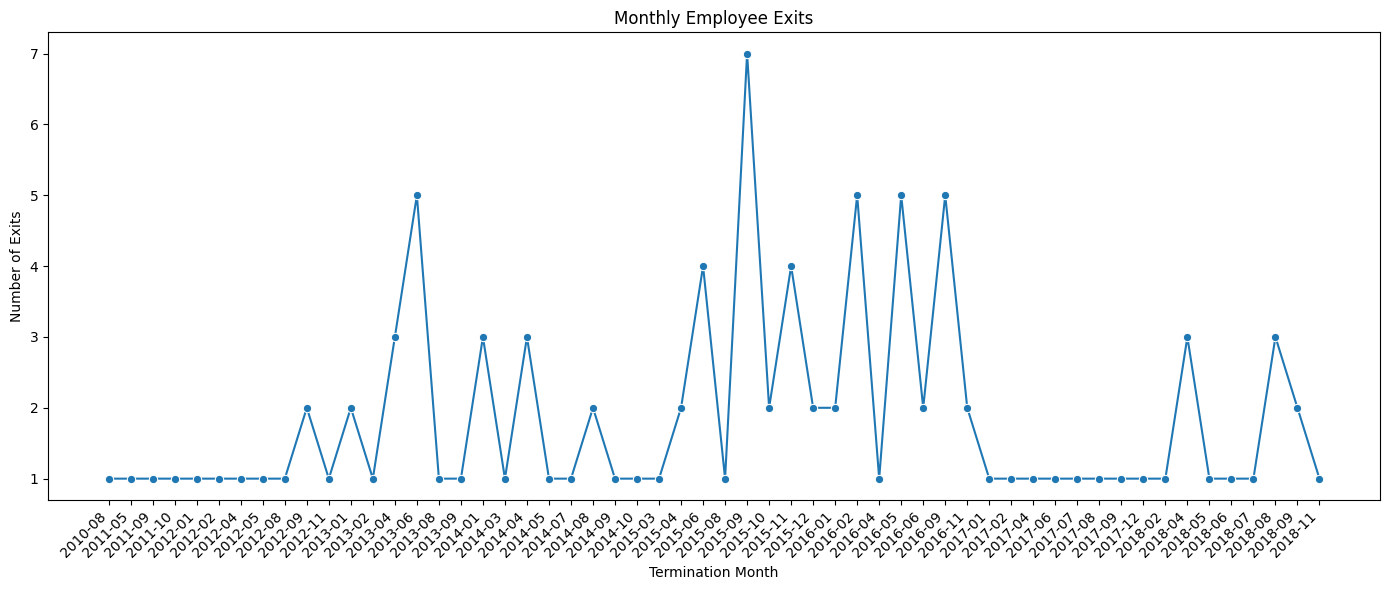


DEPARTMENT EXIT ANALYSIS
          Department  EmployeeRecords  DistinctEmployees  TerminatedEmployees  ActiveEmployees  ExitSharePct  TerminatedRecordSharePct
          Production              209                209                   83              126         79.81                     39.71
Software Engineering               11                 11                    4                7          3.85                     36.36
       Admin Offices                9                  9                    2                7          1.92                     22.22
               IT/IS               50                 50                   10               40          9.62                     20.00
               Sales               31                 31                    5               26          4.81                     16.13
    Executive Office                1                  1                    0                1          0.00                      0.00


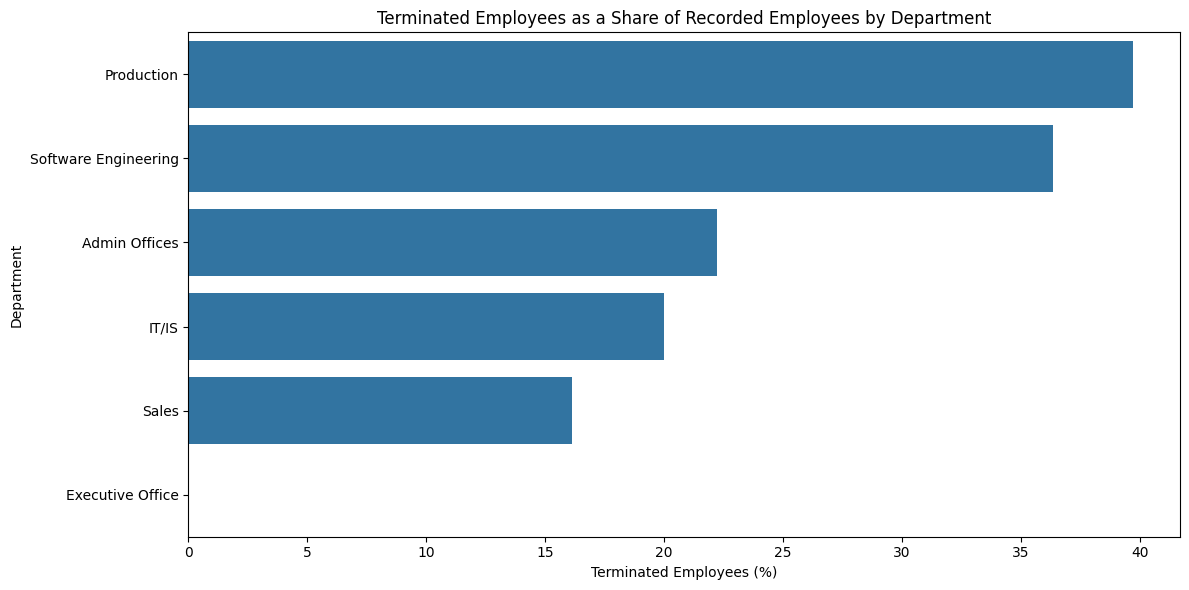


POSITION EXIT ANALYSIS
 PositionID                     Position  DistinctEmployees  TerminatedEmployees  TerminatedRecordSharePct
         19      Production Technician I                137                   52                     37.96
         20     Production Technician II                 57                   26                     45.61
         18           Production Manager                 13                    5                     38.46
          3           Area Sales Manager                 27                    4                     14.81
         24            Software Engineer                  9                    3                     33.33
          8       Database Administrator                  5                    3                     60.00
          9                 Data Analyst                  8                    2                     25.00
          2     Administrative Assistant                  3                    2                     66.67
         21  

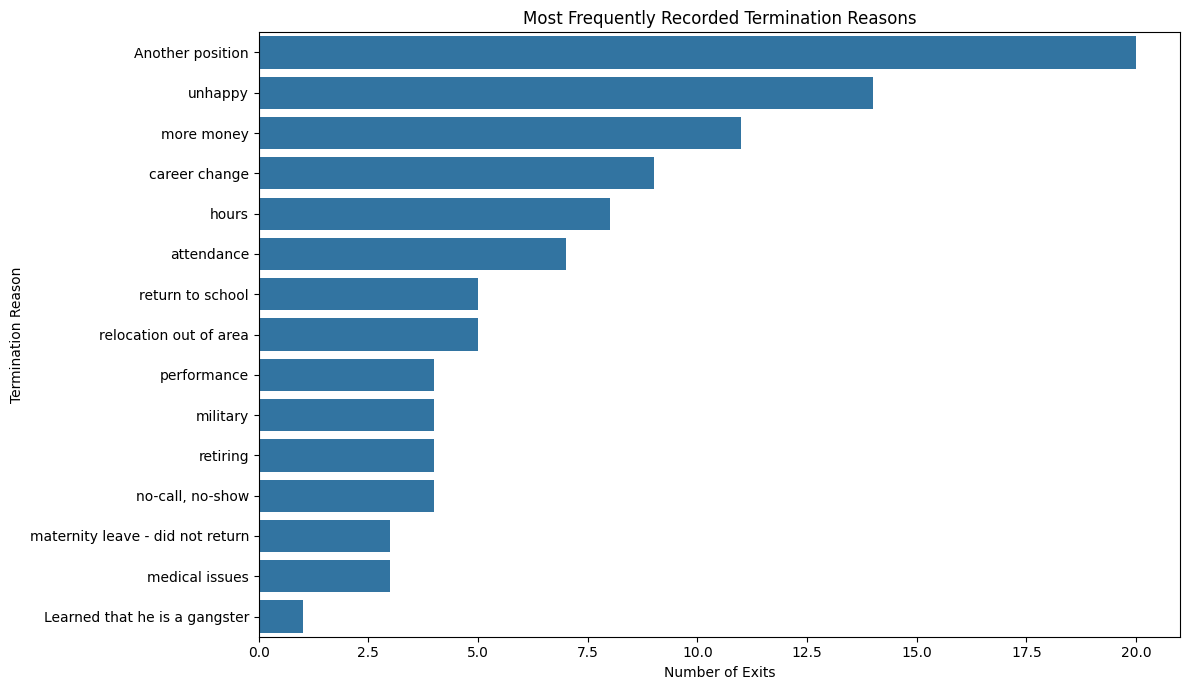


TENURE BEFORE EXIT
     TenureGroup  Exits  PercentageOfDatedExits
Less than 1 year      9                    8.65
       1–3 years     34                   32.69
       3–5 years     35                   33.65
      5–10 years     26                   25.00
   Over 10 years      0                    0.00

Median tenure before exit (years): 3.4

EXIT ANALYSIS BY SEX
Sex  DistinctEmployees  TerminatedEmployees  TerminatedRecordSharePct
  F                176                   60                     34.09
 M                 135                   44                     32.59

EXIT ANALYSIS BY MANAGERNAME
       ManagerName  DistinctEmployees  TerminatedEmployees  TerminatedRecordSharePct
          Amy Dunn                 21                   13                     61.90
    Webster Butler                 21                   13                     61.90
    Kissy Sullivan                 22                   12                     54.55
    Michael Albert                 22             

In [ ]:


# ==========================================

# Convert date columns safely
for col in ["DateofHire", "DateofTermination"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Standardise key text fields
for col in ["Department", "Position", "TermReason", "EmploymentStatus"]:
    df[col] = df[col].astype("string").str.strip()

# Identify terminated employees using available indicators.
# Termd = 1 OR a valid termination date.
termd_flag = pd.to_numeric(df["Termd"], errors="coerce")

terminated_mask = (
    termd_flag.eq(1)
    | df["DateofTermination"].notna()
)

exits = df.loc[terminated_mask].copy()

print("EMPLOYEE EXIT OVERVIEW")
print("-" * 50)
print(f"Total employee records: {len(df):,}")
print(f"Records identified as terminated: {len(exits):,}")
print(
    "Terminated records with termination dates:",
    exits["DateofTermination"].notna().sum()
)

# ==========================================
# HOW FREQUENTLY ARE EMPLOYEES LEAVING?
# ==========================================

dated_exits = exits.dropna(subset=["DateofTermination"]).copy()

dated_exits["ExitMonth"] = (
    dated_exits["DateofTermination"].dt.to_period("M").astype(str)
)

monthly_exits = (
    dated_exits.groupby("ExitMonth")
    .agg(Exits=("EmpID", "nunique"))
    .reset_index()
    .sort_values("ExitMonth")
)

monthly_exits["PreviousMonthExits"] = monthly_exits["Exits"].shift(1)

monthly_exits["MonthOnMonthChange"] = (
    monthly_exits["Exits"] - monthly_exits["PreviousMonthExits"]
)

monthly_exits["MonthOnMonthChangePct"] = np.where(
    monthly_exits["PreviousMonthExits"].gt(0),
    (
        monthly_exits["MonthOnMonthChange"]
        / monthly_exits["PreviousMonthExits"]
    ) * 100,
    np.nan
)

print("\nMONTHLY EMPLOYEE EXITS")
print(monthly_exits.to_string(index=False))

monthly_exits.to_csv(
    output_dir / "monthly_employee_exits.csv", index=False
)

# Plot monthly exits
if not monthly_exits.empty:
    plt.figure(figsize=(14, 6))
    sns.lineplot(
        data=monthly_exits,
        x="ExitMonth",
        y="Exits",
        marker="o"
    )
    plt.title("Monthly Employee Exits")
    plt.xlabel("Termination Month")
    plt.ylabel("Number of Exits")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(
        output_dir / "monthly_employee_exits.png",
        dpi=300
    )
    plt.show()

# ==========================================
# WHICH DEPARTMENTS HAVE HIGHER EXIT RATES?
# ==========================================

# Use employee-level records and exclude missing IDs from distinct counts.
department_attrition = (
    df.groupby("Department", dropna=False)
    .apply(
        lambda g: pd.Series({
            "EmployeeRecords": len(g),
            "DistinctEmployees": g["EmpID"].nunique(),
            "TerminatedEmployees": g.loc[
                terminated_mask.reindex(g.index, fill_value=False), "EmpID"
            ].nunique(),
            "ActiveEmployees": g.loc[
                g["EmploymentStatus"].str.casefold().eq("active").fillna(False),
                "EmpID"
            ].nunique()
        }),
        include_groups=False
    )
    .reset_index()
)

department_attrition["ExitSharePct"] = (
    department_attrition["TerminatedEmployees"]
    / department_attrition["TerminatedEmployees"].sum()
    * 100
).round(2)

department_attrition["TerminatedRecordSharePct"] = (
    department_attrition["TerminatedEmployees"]
    / department_attrition["DistinctEmployees"].replace(0, np.nan)
    * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "TerminatedRecordSharePct", ascending=False
)

print("\nDEPARTMENT EXIT ANALYSIS")
print(department_attrition.to_string(index=False))

department_attrition.to_csv(
    output_dir / "department_exit_analysis.csv", index=False
)

# Plot department comparison
plt.figure(figsize=(12, 6))
sns.barplot(
    data=department_attrition,
    x="TerminatedRecordSharePct",
    y="Department"
)
plt.title("Terminated Employees as a Share of Recorded Employees by Department")
plt.xlabel("Terminated Employees (%)")
plt.ylabel("Department")
plt.tight_layout()
plt.savefig(
    output_dir / "department_exit_comparison.png",
    dpi=300
)
plt.show()

# ==========================================
# WHICH POSITIONS EXPERIENCE MORE EXITS?
# ==========================================

position_attrition = (
    df.assign(_IsTerminated=terminated_mask)
    .groupby(["PositionID", "Position"], dropna=False)
    .agg(
        DistinctEmployees=("EmpID", "nunique"),
        TerminatedEmployees=(
            "EmpID",
            lambda s: s[
                terminated_mask.loc[s.index]
            ].nunique()
        )
    )
    .reset_index()
)

position_attrition["TerminatedRecordSharePct"] = (
    position_attrition["TerminatedEmployees"]
    / position_attrition["DistinctEmployees"].replace(0, np.nan)
    * 100
).round(2)

position_attrition = position_attrition.sort_values(
    "TerminatedEmployees", ascending=False
)

print("\nPOSITION EXIT ANALYSIS")
print(position_attrition.to_string(index=False))

position_attrition.to_csv(
    output_dir / "position_exit_analysis.csv", index=False
)

# ==========================================
# WHAT TERMINATION REASONS ARE RECORDED?
# ==========================================

termination_reasons = (
    exits["TermReason"]
    .fillna("Not recorded")
    .replace("", "Not recorded")
    .value_counts()
    .rename_axis("TerminationReason")
    .reset_index(name="ExitCount")
)

termination_reasons["PercentageOfExits"] = (
    termination_reasons["ExitCount"] / len(exits) * 100
).round(2) if len(exits) else 0

print("\nTERMINATION REASONS")
print(termination_reasons.to_string(index=False))

termination_reasons.to_csv(
    output_dir / "termination_reasons.csv", index=False
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=termination_reasons.head(15),
    x="ExitCount",
    y="TerminationReason"
)
plt.title("Most Frequently Recorded Termination Reasons")
plt.xlabel("Number of Exits")
plt.ylabel("Termination Reason")
plt.tight_layout()
plt.savefig(
    output_dir / "termination_reasons.png",
    dpi=300
)
plt.show()

# ==========================================
# HOW LONG DO EMPLOYEES STAY BEFORE LEAVING?
# ==========================================

tenure_exits = exits.dropna(
    subset=["DateofHire", "DateofTermination"]
).copy()

tenure_exits = tenure_exits[
    tenure_exits["DateofTermination"] >= tenure_exits["DateofHire"]
].copy()

tenure_exits["TenureYears"] = (
    (
        tenure_exits["DateofTermination"]
        - tenure_exits["DateofHire"]
    ).dt.days / 365.25
)

tenure_exits["TenureGroup"] = pd.cut(
    tenure_exits["TenureYears"],
    bins=[-0.001, 1, 3, 5, 10, np.inf],
    labels=[
        "Less than 1 year",
        "1–3 years",
        "3–5 years",
        "5–10 years",
        "Over 10 years"
    ],
    right=True
)

tenure_summary = (
    tenure_exits.groupby("TenureGroup", observed=False)
    .agg(Exits=("EmpID", "nunique"))
    .reset_index()
)

tenure_summary["PercentageOfDatedExits"] = (
    tenure_summary["Exits"]
    / tenure_summary["Exits"].sum()
    * 100
).round(2)

print("\nTENURE BEFORE EXIT")
print(tenure_summary.to_string(index=False))

print(
    "\nMedian tenure before exit (years):",
    round(tenure_exits["TenureYears"].median(), 2)
)

tenure_summary.to_csv(
    output_dir / "tenure_before_exit.csv", index=False
)

# ==========================================
# 7. OPTIONAL: EXITS BY GENDER AND MANAGER
# ==========================================

for group_col in ["Sex", "ManagerName"]:
    group_summary = (
        df.assign(_IsTerminated=terminated_mask)
        .groupby(group_col, dropna=False)
        .agg(
            DistinctEmployees=("EmpID", "nunique"),
            TerminatedEmployees=(
                "EmpID",
                lambda s: s[terminated_mask.loc[s.index]].nunique()
            )
        )
        .reset_index()
    )

    group_summary["TerminatedRecordSharePct"] = (
        group_summary["TerminatedEmployees"]
        / group_summary["DistinctEmployees"].replace(0, np.nan)
        * 100
    ).round(2)

    group_summary = group_summary.sort_values(
        "TerminatedEmployees", ascending=False
    )

    print(f"\nEXIT ANALYSIS BY {group_col.upper()}")
    print(group_summary.to_string(index=False))

    safe_name = group_col.lower().replace(" ", "_")
    group_summary.to_csv(
        output_dir / f"exit_analysis_by_{safe_name}.csv",
        index=False
    )

print(f"\nAll outputs saved to: {output_dir.resolve()}")

### Observations — Employee exits, exit-prone groups, and recorded reasons

- **104 of 311 employees (33.44%) have been identified as terminated** in this dataset, and all 104 have a recorded termination date. This is the proportion of records marked as terminated in the dataset; it is not an annual attrition rate.
- **Production accounts for 83 of the 104 exits (79.81% of all recorded exits)**, reflecting its much larger workforce. Within-department terminated-record shares are 39.71% for Production, 36.36% for Software Engineering, 22.22% for Admin Offices, 20.00% for IT/IS, and 16.13% for Sales. Software Engineering has only 11 records, so its percentage should be interpreted cautiously.
- **Production Technician I recorded 52 exits and Production Technician II recorded 26.** These are the largest exit counts by position. Some small job groups show high percentages—for example, Database Administrator has 3 exits among 5 records (60%)—but small group sizes make these percentages unstable.
- **The most common recorded termination reason is “Another position” (20 exits; 19.23%)**, followed by “unhappy” (14; 13.46%), “more money” (11; 10.58%), “career change” (9; 8.65%), and “hours” (8; 7.69%). These top five reasons account for 62 exits (59.62% of recorded exits). The reasons are free-text categories and should be standardised before executive reporting.
- **Median tenure before exit is 3.4 years.** Thirty-four exits (32.69%) occurred after 1–3 years and 35 (33.65%) after 3–5 years; together, 66.34% of dated exits occurred between 1 and 5 years of tenure. Nine exits (8.65%) occurred within the first year.
- The terminated-record share is similar across the recorded sex groups: 34.09% for F and 32.59% for M. This descriptive difference is small and does not establish a meaningful or causal difference.
- Manager-level percentages vary, but should be treated as **signals for confidential follow-up, not evidence of manager-caused turnover**. Differences in team size, role mix, tenure, and reason for leaving may explain some of the variation.

**Interpretation:** the largest absolute retention opportunity is likely in Production because of its size, while the recorded reasons suggest reviewing career progression, employee sentiment, compensation competitiveness, and working hours. These are hypotheses to investigate with HR interviews and additional data, not proven causes.

## 3. How is recorded salary distributed across departments and positions, and where are the largest concentrations of salary costs?

COMPENSATION AND SALARY ANALYSIS
Total employee records: 311
Records with valid employee IDs and numeric salaries: 311
Missing or non-numeric salaries: 0
Negative salary records: 0

OVERALL SALARY SUMMARY
                              Metric        Value
Employee records with valid salaries 3.110000e+02
               Total recorded salary 2.146543e+07
                         Mean salary 6.902068e+04
                       Median salary 6.281000e+04
                      Minimum salary 4.504600e+04
                      Maximum salary 2.500000e+05
                     25th percentile 5.550150e+04
                     75th percentile 7.203600e+04
           Salary standard deviation 2.515664e+04

SALARY DISTRIBUTION BY DEPARTMENT
          Department  EmployeeCount  TotalRecordedSalary  MeanSalary  MedianSalary  MinimumSalary  MaximumSalary  SalaryStdDev  SalaryCostSharePct
          Production            209             12530291    59953.55       59472.0          45046         170500 

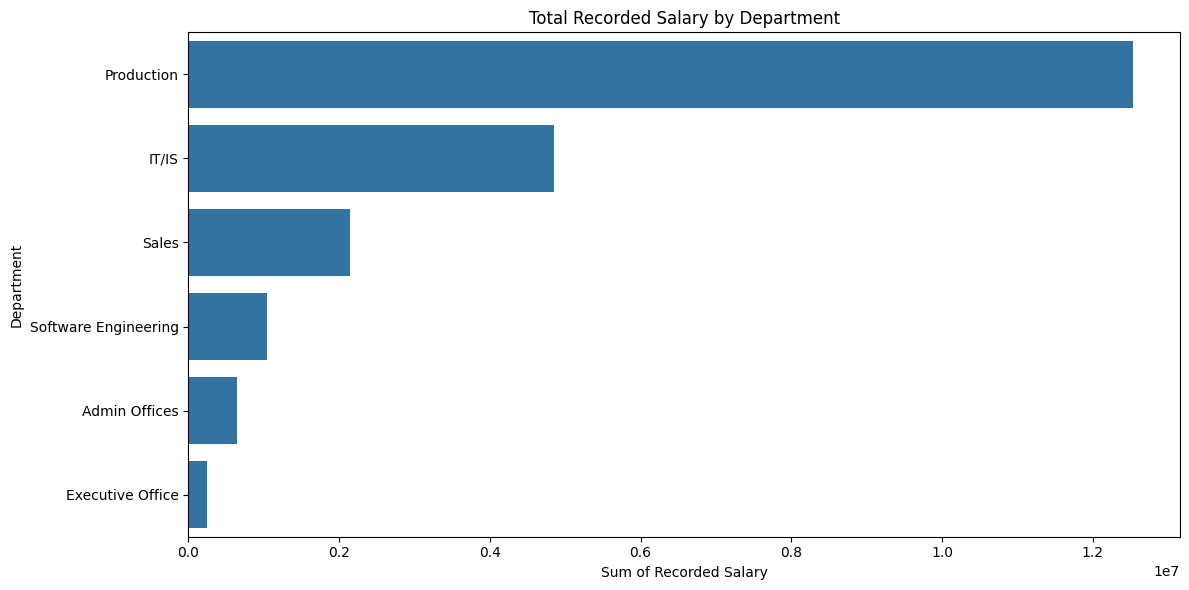

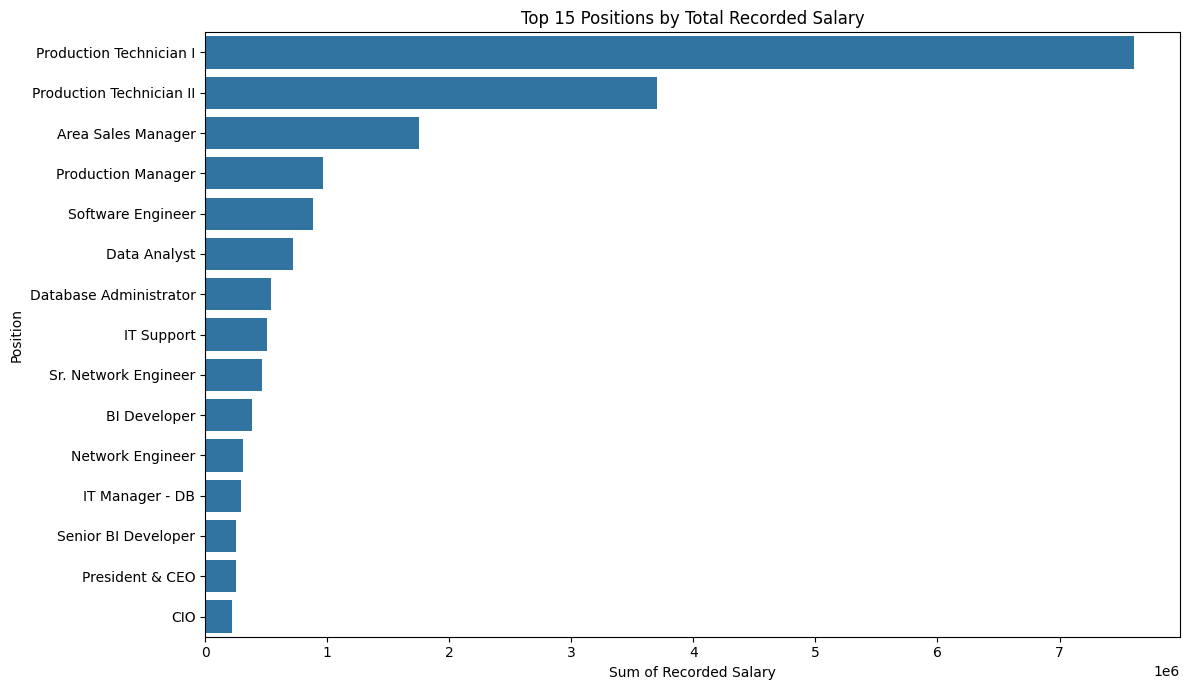

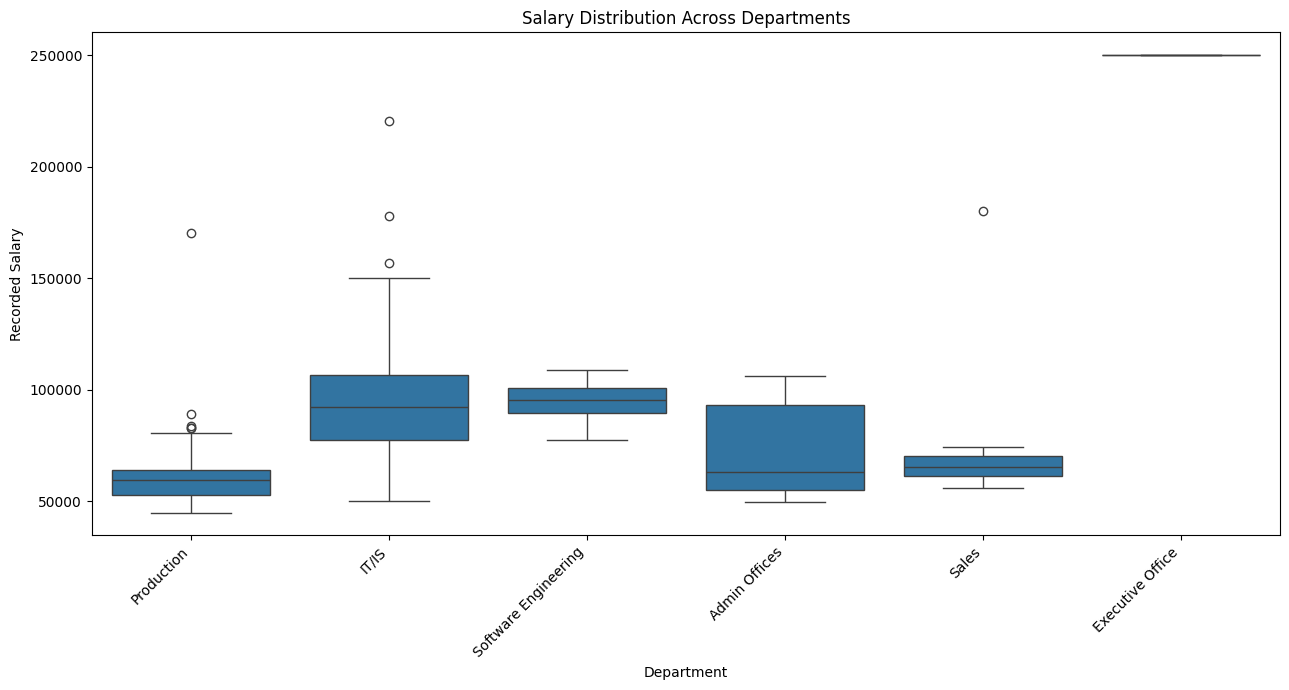


POTENTIAL SALARY OUTLIERS
Lower IQR bound: 30,699.75
Upper IQR bound: 96,837.75
Potential outlier records: 29

All outputs saved to: /Users/mac/Desktop/Workforce-Intelligence-HR-Analytics-Employee-Lifecycle-Compensation-and-Performance-Analysis/Notebook/output


In [ ]:

# Convert Salary to numeric
df["Salary"] = pd.to_numeric(
    df["Salary"].astype("string").str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)

# Exclude missing employee IDs and missing salaries from salary metrics
salary_df = df.dropna(subset=["EmpID", "Salary"]).copy()

# Flag invalid negative salaries for review
invalid_salary = salary_df[salary_df["Salary"] < 0].copy()

print("=" * 60)
print("COMPENSATION AND SALARY ANALYSIS")
print("=" * 60)

print(f"Total employee records: {len(df):,}")
print(f"Records with valid employee IDs and numeric salaries: {len(salary_df):,}")
print(f"Missing or non-numeric salaries: {df['Salary'].isna().sum():,}")
print(f"Negative salary records: {len(invalid_salary):,}")

invalid_salary.to_csv(
    output_dir / "invalid_salary_records.csv",
    index=False
)

# Use non-negative salaries for descriptive compensation metrics
valid_salary_df = salary_df[salary_df["Salary"] >= 0].copy()

# ==========================================
# OVERALL SALARY DISTRIBUTION
# ==========================================

overall_salary = pd.DataFrame({
    "Metric": [
        "Employee records with valid salaries",
        "Total recorded salary",
        "Mean salary",
        "Median salary",
        "Minimum salary",
        "Maximum salary",
        "25th percentile",
        "75th percentile",
        "Salary standard deviation"
    ],
    "Value": [
        valid_salary_df["EmpID"].nunique(),
        valid_salary_df["Salary"].sum(),
        valid_salary_df["Salary"].mean(),
        valid_salary_df["Salary"].median(),
        valid_salary_df["Salary"].min(),
        valid_salary_df["Salary"].max(),
        valid_salary_df["Salary"].quantile(0.25),
        valid_salary_df["Salary"].quantile(0.75),
        valid_salary_df["Salary"].std()
    ]
})

print("\nOVERALL SALARY SUMMARY")
print(overall_salary.to_string(index=False))

overall_salary.to_csv(
    output_dir / "overall_salary_summary.csv",
    index=False
)

# ==========================================
# SALARY DISTRIBUTION BY DEPARTMENT
# ==========================================

department_salary = (
    valid_salary_df.groupby("Department", dropna=False)
    .agg(
        EmployeeCount=("EmpID", "nunique"),
        TotalRecordedSalary=("Salary", "sum"),
        MeanSalary=("Salary", "mean"),
        MedianSalary=("Salary", "median"),
        MinimumSalary=("Salary", "min"),
        MaximumSalary=("Salary", "max"),
        SalaryStdDev=("Salary", "std")
    )
    .reset_index()
)

total_salary = department_salary["TotalRecordedSalary"].sum()

department_salary["SalaryCostSharePct"] = (
    department_salary["TotalRecordedSalary"] / total_salary * 100
).round(2) if total_salary else 0

department_salary["MeanSalary"] = department_salary["MeanSalary"].round(2)
department_salary["MedianSalary"] = department_salary["MedianSalary"].round(2)
department_salary["SalaryStdDev"] = department_salary["SalaryStdDev"].round(2)

department_salary = department_salary.sort_values(
    "TotalRecordedSalary", ascending=False
)

print("\nSALARY DISTRIBUTION BY DEPARTMENT")
print(department_salary.to_string(index=False))

department_salary.to_csv(
    output_dir / "salary_by_department.csv",
    index=False
)

# ==========================================
# 4. SALARY DISTRIBUTION BY POSITION
# ==========================================

position_salary = (
    valid_salary_df.groupby(
        ["PositionID", "Position"],
        dropna=False
    )
    .agg(
        EmployeeCount=("EmpID", "nunique"),
        TotalRecordedSalary=("Salary", "sum"),
        MeanSalary=("Salary", "mean"),
        MedianSalary=("Salary", "median"),
        MinimumSalary=("Salary", "min"),
        MaximumSalary=("Salary", "max")
    )
    .reset_index()
)

position_salary["SalaryCostSharePct"] = (
    position_salary["TotalRecordedSalary"] / total_salary * 100
).round(2) if total_salary else 0

position_salary["MeanSalary"] = position_salary["MeanSalary"].round(2)
position_salary["MedianSalary"] = position_salary["MedianSalary"].round(2)

position_salary = position_salary.sort_values(
    "TotalRecordedSalary", ascending=False
)

print("\nSALARY DISTRIBUTION BY POSITION")
print(position_salary.to_string(index=False))

position_salary.to_csv(
    output_dir / "salary_by_position.csv",
    index=False
)

# ==========================================
# DEPARTMENT AND POSITION SALARY CONCENTRATION
# ==========================================

department_position_salary = (
    valid_salary_df.groupby(
        ["Department", "Position"],
        dropna=False
    )
    .agg(
        EmployeeCount=("EmpID", "nunique"),
        TotalRecordedSalary=("Salary", "sum"),
        MeanSalary=("Salary", "mean"),
        MedianSalary=("Salary", "median")
    )
    .reset_index()
)

department_position_salary["SalaryCostSharePct"] = (
    department_position_salary["TotalRecordedSalary"]
    / total_salary * 100
).round(2) if total_salary else 0

department_position_salary = department_position_salary.sort_values(
    "TotalRecordedSalary", ascending=False
)

print("\nTOP 15 DEPARTMENT-POSITION SALARY CONCENTRATIONS")
print(department_position_salary.head(15).to_string(index=False))

department_position_salary.to_csv(
    output_dir / "salary_by_department_and_position.csv",
    index=False
)

# ==========================================
# 6. SALARY CONCENTRATION BY EMPLOYEE COUNT
# ==========================================

department_salary["AverageSalaryRank"] = (
    department_salary["MeanSalary"].rank(
        ascending=False, method="dense"
    ).astype(int)
)

department_salary["TotalSalaryRank"] = (
    department_salary["TotalRecordedSalary"].rank(
        ascending=False, method="dense"
    ).astype(int)
)

print("\nTOP 5 DEPARTMENTS BY TOTAL RECORDED SALARY")
print(
    department_salary.nlargest(5, "TotalRecordedSalary")[
        ["Department", "EmployeeCount", "TotalRecordedSalary",
         "SalaryCostSharePct", "MeanSalary", "MedianSalary"]
    ].to_string(index=False)
)

print("\nTOP 5 POSITIONS BY TOTAL RECORDED SALARY")
print(
    position_salary.head(5)[
        ["Position", "EmployeeCount", "TotalRecordedSalary",
         "SalaryCostSharePct", "MeanSalary", "MedianSalary"]
    ].to_string(index=False)
)

# ==========================================
#  VISUALISE TOTAL SALARY BY DEPARTMENT
# ==========================================

plt.figure(figsize=(12, 6))
sns.barplot(
    data=department_salary,
    x="TotalRecordedSalary",
    y="Department"
)
plt.title("Total Recorded Salary by Department")
plt.xlabel("Sum of Recorded Salary")
plt.ylabel("Department")
plt.tight_layout()
plt.savefig(
    output_dir / "total_salary_by_department.png",
    dpi=300
)
plt.show()

# ==========================================
# 8. VISUALISE TOP 15 POSITIONS BY TOTAL SALARY
# ==========================================

top_positions = position_salary.head(15).copy()

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_positions,
    x="TotalRecordedSalary",
    y="Position"
)
plt.title("Top 15 Positions by Total Recorded Salary")
plt.xlabel("Sum of Recorded Salary")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig(
    output_dir / "top_positions_by_total_salary.png",
    dpi=300
)
plt.show()

# ==========================================
# COMPARE SALARY DISTRIBUTIONS BY DEPARTMENT
# ==========================================

plt.figure(figsize=(13, 7))
sns.boxplot(
    data=valid_salary_df,
    x="Department",
    y="Salary"
)
plt.title("Salary Distribution Across Departments")
plt.xlabel("Department")
plt.ylabel("Recorded Salary")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    output_dir / "salary_distribution_by_department.png",
    dpi=300
)
plt.show()

# ==========================================
# CHECK EXTREME SALARY VALUES
# ==========================================

q1 = valid_salary_df["Salary"].quantile(0.25)
q3 = valid_salary_df["Salary"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

salary_outliers = valid_salary_df[
    (valid_salary_df["Salary"] < lower_bound)
    | (valid_salary_df["Salary"] > upper_bound)
].copy()

print("\nPOTENTIAL SALARY OUTLIERS")
print(f"Lower IQR bound: {lower_bound:,.2f}")
print(f"Upper IQR bound: {upper_bound:,.2f}")
print(f"Potential outlier records: {len(salary_outliers):,}")

salary_outliers.to_csv(
    output_dir / "potential_salary_outliers.csv",
    index=False
)

print(f"\nAll outputs saved to: {output_dir.resolve()}")

### Observations — Salary distribution and salary concentration

- All **311 employee records have numeric, non-negative salary values** in this analysis; no missing/non-numeric or negative salaries were reported.
- The **sum of recorded salary values is 21,465,433**. The mean is approximately **69,020.68**, while the median is **62,810**. The mean being higher than the median indicates that higher salary values pull the average upward.
- Recorded salaries range from **45,046 to 250,000**. The interquartile range check flagged **29 potential outliers** above the upper IQR threshold of 96,837.75 (the lower bound was 30,699.75). These are statistical flags for review, not automatically errors; senior and specialist roles may legitimately have higher salaries.
- **Production has the largest total recorded salary concentration: 12,530,291 (58.37% of the total)** across 209 employees. This reflects its large share of the workforce (67.20%); its mean salary is 59,953.55 and median is 59,472.
- **IT/IS has the second-largest salary concentration: 4,853,232 (22.61%)** across 50 employees. Its mean salary (97,064.64) is substantially higher than Production’s, and its median is 92,328.50. This suggests a higher salary profile per employee, which may reflect differences in job mix and skill requirements.
- Sales accounts for 2,140,899 (9.97%) of recorded salary values, with a mean of 69,061.26. Software Engineering has a mean of 94,989.45 across 11 employees and represents 4.87% of the recorded salary total.
- **Production Technician I is the largest position-level concentration**, with 7,606,812 across 137 employees (35.44% of total recorded salary). Production Technician II accounts for 3,698,856 across 57 employees (17.23%). Together, these two roles account for 52.67% of the total recorded salary values.
- The Executive Office has one employee with a recorded salary of 250,000. That single record should not be used to make broad comparisons about an entire department.

**Interpretation:** the largest recorded salary concentration is in Production because it employs most of the workforce. IT/IS has a smaller workforce but a higher average salary. These findings describe the distribution of salary values; they do not establish payroll expenditure, pay equity, or whether salaries are competitive without currency, salary-period, grade, and external benchmark context.

# Overall conclusion

The analysis of 311 employee records shows a workforce concentrated in Production, which represents 67.20% of the employee register and 58.37% of the total recorded salary values. There are 207 active employees and 104 terminated employees in the dataset. The reconstructed headcount trend reaches a peak of 246 in March 2015 and falls to 207 by November 2018. Production also accounts for 79.81% of recorded exits, although this large share partly reflects its much larger workforce.

The recorded termination reasons are led by “Another position,” “unhappy,” “more money,” “career change,” and “hours.” The median tenure before exit is 3.4 years, with about two-thirds of dated exits occurring between one and five years of tenure. These patterns point to retention questions around career progression, employee experience, compensation, and working conditions that warrant further investigation.

Recorded salary values total 21,465,433, with a mean of 69,020.68 and a median of 62,810. Production has the largest total salary concentration because it has the largest workforce, while IT/IS has a higher mean salary. The salary outlier check flagged 29 records for review, but these should not be removed without validating job level and pay context.

These findings are descriptive. Because the dataset is an employee-level snapshot with historical dates, it does not by itself establish the causes of turnover, true period-specific attrition rates, payroll expenditure, or pay equity. The status reconciliation logic also needs the label correction described above before its results can be relied upon.

# Recommendations

1. **Prioritise retention analysis in Production.** Review exit reasons, tenure, shift or working-hour arrangements, supervisor/team context, and role-specific conditions for Production Technician I and II. Production has the largest absolute number of exits, so even modest improvement could affect many employees.
2. **Investigate the leading recorded exit reasons.** Conduct structured exit-interview coding for “Another position,” “unhappy,” “more money,” “career change,” and “hours.” Standardise free-text categories so HR can monitor reason trends consistently and distinguish voluntary, involuntary, and other exits.
3. **Review the 1–5 year employee lifecycle.** Since 66.34% of dated exits occurred between one and five years of tenure, assess onboarding, career paths, training, internal mobility, manager check-ins, and compensation progression during this period.
4. **Build a consistent attrition KPI.** For each month or year, calculate exits during the period divided by average headcount during the same period. Where possible, segment by department and role and compare like-for-like periods; do not label the terminated share of the full dataset as annual attrition.
5. **Review compensation using job-relevant comparisons.** Compare salaries within equivalent positions, levels, and tenure bands, and verify salary currency and period. Investigate the 29 IQR-flagged values as exceptions—not presumed errors—and use an appropriate external benchmark before drawing market-competitiveness conclusions.
6. **Use manager-level patterns as a diagnostic prompt, not a performance verdict.** Privately review teams with higher recorded exit shares alongside team size, role mix, tenure, and exit reasons. Avoid ranking managers without sufficient context and adequate sample sizes.
7. **Strengthen HR data controls.** Correct and rerun the termination-status reconciliation logic, review the 8 missing `ManagerID` values, document KPI definitions, and establish repeatable checks for employee IDs, dates, status flags, and standardised termination reasons.
8. **Improve workforce planning with a monthly dashboard.** Track active headcount, hires, exits, net change, average headcount, attrition rate, salary concentration, and reason-for-exit mix by department and position. Clearly label reconstructed historical headcount and document assumptions.

## Executive takeaway

The most actionable signal is the concentration of workforce and exits in Production, combined with recorded reasons that include alternative employment, dissatisfaction, pay, career change, and working hours. HR should validate the underlying data, investigate these themes with the relevant teams, and establish consistent monthly workforce KPIs before making causal or budget decisions.